In [1]:
import pickle as pk
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import ks_2samp

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
)

SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
warnings.filterwarnings("ignore", category=FutureWarning)

# Week 3 Helper Notebook
This exploration should produce AT LEAST two figures , which you should include in the progress report and make look nice using seaborn (feel free to use AI to help with plotting). For example:
- A table or figure showing the most stable and unstable features.
- At least one comparison across feature categories.
- Different instability metrics. 


Guiding questions to discuss with your group: 

1. What are at least three reasonable definitions of feature instability?
2. Do those definitions identify the same features?
4. Are certain EHR feature categories systematically more unstable?
5. Does instability depend on the prediction outcome?
7. Which instability metrics seem most promising to investigate further?

### Group implementation notes

This version keeps the structure of the official Week 3 helper notebook and is
set up to run on the **full eICU data** produced by `week1_explore_eicu_data.ipynb`.

It also incorporates two lessons from our demo-data smoke test:

- Very sparse features should not be labeled "stable" just because there was
  too little data to estimate their instability.
- A feature receives a 3-metric combined instability score only when all three
  instability measures have adequate hospital coverage.

The notebook therefore filters features using **source hospitals only**, records
how many hospitals support each metric, and leaves combined scores missing when
the evidence is insufficient.

It also keeps held-out hospitals completely separate from feature-instability
measurement and feature ranking.

## Step 1: Load eICU data

In [2]:
def find_data_file(filename):
    """
    Find project data without assuming everybody launches Jupyter from the
    same directory.

    This supports the two layouts we have seen:
      1. <repo>/data/<file>
      2. <repo parent>/data/<file>
    """
    cwd = Path.cwd().resolve()
    candidates = []

    for base in [cwd, *list(cwd.parents)[:5]]:
        candidates.append(base / "data" / filename)

    # Keep the official helper notebook's relative path near the front.
    candidates = [
        (cwd / "../../data" / filename).resolve(),
        (cwd / "../../../data" / filename).resolve(),
        *candidates,
    ]

    seen = set()
    for path in candidates:
        path = path.resolve()
        if path in seen:
            continue
        seen.add(path)
        if path.exists():
            return path

    tried = "\n".join(f"  - {p}" for p in seen)
    raise FileNotFoundError(
        f"Could not find {filename}. Checked:\n{tried}\n\n"
        "Run week1_explore_eicu_data.ipynb first or update the data path."
    )


FEATURE_NAMES_PATH = find_data_file("feature_names.pkl")
CLEAN_DATA_PATH = find_data_file("clean_dataset.parquet")

feature_sets = pk.load(open(FEATURE_NAMES_PATH, "rb"))
patient_agg = pd.read_parquet(CLEAN_DATA_PATH)

print("feature_names.pkl:", FEATURE_NAMES_PATH)
print("clean_dataset.parquet:", CLEAN_DATA_PATH)
print("Dataset shape:", patient_agg.shape)
patient_agg.head()

feature_names.pkl: /Users/gabrielarm300/data/feature_names.pkl
clean_dataset.parquet: /Users/gabrielarm300/data/clean_dataset.parquet
Dataset shape: (135778, 2167)


,patienthealthsystemstayid,gender,age,ethnicity,hospitalid,hospitaldischargeyear,mortality_at48h,hospital_numbedscategory,hospital_region,"admissiondx_ARDS-adult respiratory distress syndrome, non-cardiogenic pulmonary edema",admissiondx_Abdomen only trauma,admissiondx_Abdomen/extremity trauma,admissiondx_Abdomen/face trauma,admissiondx_Abdomen/multiple trauma,admissiondx_Abdomen/pelvis trauma,admissiondx_Abdomen/spinal trauma,admissiondx_Ablation or mapping of cardiac conduction pathway,"admissiondx_Abscess, neurologic","admissiondx_Abscess/infection-cranial, surgery for",admissiondx_Acid-base/electrolyte disturbance,admissiondx_Addisons disease,admissiondx_Adrenal neoplasm (including pheochromocytoma),admissiondx_Adrenalectomy,admissiondx_Alcohol withdrawal,admissiondx_Amputation (non-traumatic),admissiondx_Amyotrophic lateral sclerosis,admissiondx_Anaphylaxis,"admissiondx_Anastomosis, vascular",admissiondx_Anemia,"admissiondx_Aneurysm repair, ventricular","admissiondx_Aneurysm, abdominal aortic","admissiondx_Aneurysm, abdominal aortic; with dissection","admissiondx_Aneurysm, abdominal aortic; with rupture","admissiondx_Aneurysm, dissecting aortic","admissiondx_Aneurysm, thoracic aortic","admissiondx_Aneurysm, thoracic aortic; with dissection","admissiondx_Aneurysm, thoracic aortic; with rupture","admissiondx_Aneurysm/pseudoaneurysm, other","admissiondx_Aneurysms, repair of other (except ventricular)","admissiondx_Angina, stable (asymp or stable pattern of symptoms w/meds)","admissiondx_Angina, unstable (angina interferes w/quality of life or meds are tolerated poorly)",admissiondx_Aortic and Mitral valve replacement,admissiondx_Aortic valve replacement (isolated),"admissiondx_Apnea, sleep","admissiondx_Apnea-sleep; surgery for (i.e., UPPP - uvulopalatopharyngoplasty)",admissiondx_Appendectomy,"admissiondx_Arrest, respiratory (without cardiac arrest)","admissiondx_Arteriovenous malformation, surgery for","admissiondx_Arthritis, rheumatoid","admissiondx_Arthritis, septic",...,calcium,cd 4,chloride,cortisol,creatinine,direct bilirubin,eos,ethanol,fibrinogen,folate,free T4,glucose,glucose CSF,haptoglobin,ionized calcium,lactate,lipase,lymphs,magnesium,monos,myoglobin,pH,paCO2,paO2,phosphate,platelets x 1000,polys,potassium,prealbumin,prolactin,protein CSF,protein C,protein S,reticulocyte count,salicylate,serum ketones,serum osmolality,sodium,total bilirubin,total cholesterol,total protein,transferrin,triglycerides,troponin I,troponin T,uric acid,urinary creatinine,urinary osmolality,urinary sodium,urinary specific gravity
0,128919,Female,70,Caucasian,59,2015,1,<100,Midwest,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,9.000000,NaN,101.500000,NaN,2.125000,NaN,0.5,NaN,NaN,NaN,NaN,113.0,NaN,NaN,NaN,NaN,NaN,12.500000,NaN,16.500000,NaN,NaN,NaN,NaN,NaN,211.000000,70.5,4.100000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,139.000000,3.35,NaN,7.10,NaN,NaN,NaN,NaN,8.1,NaN,NaN,NaN,NaN
1,128927,Female,52,Caucasian,60,2015,0,<100,Midwest,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,8.100000,NaN,107.750000,NaN,0.700000,NaN,3.0,234.0,NaN,NaN,NaN,74.5,NaN,NaN,NaN,NaN,NaN,45.000000,1.90,7.000000,NaN,NaN,NaN,NaN,NaN,273.000000,45.0,3.750000,NaN,NaN,NaN,NaN,NaN,NaN,2.3,NaN,NaN,144.500000,0.40,NaN,7.40,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,128941,Male,68,Caucasian,73,2015,0,>= 500,Midwest,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,9.200000,NaN,103.500000,NaN,2.725000,0.1,0.5,NaN,NaN,NaN,NaN,151.5,NaN,NaN,NaN,1.666667,NaN,3.500000,1.20,4.500000,NaN,NaN,NaN,NaN,NaN,265.500000,91.5,4.300000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,134.500000,0.40,NaN,7.45,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.018
3,128943,Male,71,Caucasian,67,2015,0,NaN,Midwest,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,9.000000,NaN,98.000000,NaN,0.865000,NaN,0.0,NaN,NaN,NaN,NaN,153.0,NaN,NaN,NaN,0.800000,NaN,3.000000,NaN,4.500000,NaN,7

In [3]:
# This distinction of numerical (continuous), binary, and categorical
# columns may be useful throughout the project.
all_num_cols = (
    feature_sets['labs'].tolist()
    + feature_sets['vitals'].tolist()
    + ['age', 'admissionheight', 'admissionweight']
)

all_bin_cols = (
    feature_sets['icd10_before24h'].tolist()
    + feature_sets['admissiondx'].tolist()
)

all_cat_cols = [
    # 'hospital_region',
    'ethnicity',
    'gender',
    'hospital_numbedscategory',
    'hospitaldischargeyear',
    # 'hospitalid'
]

# Keep only columns that are actually present in this version of the dataset.
all_num_cols = [c for c in all_num_cols if c in patient_agg.columns]
all_bin_cols = [c for c in all_bin_cols if c in patient_agg.columns]
all_cat_cols = [c for c in all_cat_cols if c in patient_agg.columns]

# Feature -> broader EHR category.
feature_group = {}
for c in feature_sets['labs'].tolist():
    if c in patient_agg.columns:
        feature_group[c] = 'labs'
for c in feature_sets['vitals'].tolist():
    if c in patient_agg.columns:
        feature_group[c] = 'vitals'
for c in feature_sets['icd10_before24h'].tolist():
    if c in patient_agg.columns:
        feature_group[c] = 'icd10_before24h'
for c in feature_sets['admissiondx'].tolist():
    if c in patient_agg.columns:
        feature_group[c] = 'admissiondx'
for c in ['age', 'admissionheight', 'admissionweight']:
    if c in patient_agg.columns:
        feature_group[c] = 'demographic'

feature_type = {c: 'continuous' for c in all_num_cols}
feature_type.update({c: 'binary' for c in all_bin_cols})

print("Continuous features:", len(all_num_cols))
print("Binary features:", len(all_bin_cols))
print("Categorical columns available:", all_cat_cols)

Continuous features: 213
Binary features: 1167
Categorical columns available: ['ethnicity', 'gender', 'hospital_numbedscategory', 'hospitaldischargeyear']


In [4]:
# For privacy, eICU records patients older than 89 using the string "> 89".
if 'age' in patient_agg.columns:
    patient_agg.loc[patient_agg.age == '> 89', 'age'] = '90'
    patient_agg['age'] = pd.to_numeric(patient_agg['age'], errors='coerce')

# Make the candidate continuous/binary features numeric.
for c in all_num_cols + all_bin_cols:
    patient_agg[c] = pd.to_numeric(patient_agg[c], errors='coerce')

# Avoid accidentally using outcomes or identifiers as model features.
hospital_col = 'hospitalid'
if hospital_col not in patient_agg.columns:
    raise KeyError("Expected a hospitalid column in clean_dataset.parquet.")

outcome_candidates = [
    c for c in patient_agg.columns
    if c == 'mortality_at48h' or c.startswith('label_')
]

print("Candidate outcomes found:", len(outcome_candidates))
print(outcome_candidates[:30])

Candidate outcomes found: 780
['mortality_at48h', 'label_A02.0', 'label_A03.9', 'label_A04.4', 'label_A04.5', 'label_A04.7', 'label_A05.9', 'label_A09', 'label_A15.0', 'label_A18.84', 'label_A31.9', 'label_A32.11', 'label_A39.0', 'label_A41.9', 'label_A48.1', 'label_A48.3', 'label_A86', 'label_A87.9', 'label_A92.31', 'label_B00.2', 'label_B00.4', 'label_B02.9', 'label_B15.9', 'label_B17.1', 'label_B17.9', 'label_B19.10', 'label_B20', 'label_B25.0', 'label_B25.8', 'label_B27.09']


## Step 2: Prediction setup

In [5]:
# Prediction setup
#
# If your group already agreed on exact held-out hospitals from Week 2,
# replace EXPLICIT_HELDOUT_SPLITS with a list of lists, e.g.
# EXPLICIT_HELDOUT_SPLITS = [[73, 122, 154], [141, 176, 252]]
#
# Otherwise, the notebook creates three reproducible hospital-level splits.
# We do NOT choose splits based on which one gives the largest gap.

REQUESTED_OUTCOMES = ['mortality_at48h']
N_OUTCOMES = 2
N_SPLITS = 3
N_HELDOUT_HOSPITALS = 5
EXPLICIT_HELDOUT_SPLITS = None

# Full-data hospital eligibility.
MIN_HOSPITAL_N = 200
MIN_HOSPITAL_POSITIVES = 20
MIN_HOSPITAL_NEGATIVES = 20

# Feature evidence thresholds. These are deliberately stricter than the
# demo-data version because sparse demo features received misleading scores.
MIN_FEATURE_NONMISSING_RATE = 0.05
MIN_FEATURE_NONMISSING_COUNT = 500
MIN_HOSPITALS_WITH_FEATURE = 5
MIN_NONMISSING_PER_HOSPITAL = 30
MIN_HOSPITALS_FOR_INSTABILITY = 5

# Relationship-to-outcome instability needs both classes within a hospital.
MIN_POSITIVES_FOR_RELATIONSHIP = 5
MIN_NEGATIVES_FOR_RELATIONSHIP = 5

# Limit the number of very high-dimensional diagnosis features so the notebook
# remains reasonable to run on a laptop. Selection is based on SOURCE data only.
MAX_FEATURES_PER_GROUP = 40
MAX_TOTAL_FEATURES = 140

# Optional Week 3 bonus: utility-vs-instability comparison.
TOP_K_FEATURES = 20
LAMBDA_INSTABILITY = 0.50

# Sampling for the KS calculations.
MAX_KS_SAMPLE_PER_HOSPITAL = 750
MAX_KS_REFERENCE_SAMPLE = 3000

INTERNAL_VALIDATION_SIZE = 0.20
OUTPUT_DIR = Path("week3_full_data_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def coerce_binary(series):
    if pd.api.types.is_bool_dtype(series):
        return series.astype(float)

    numeric = pd.to_numeric(series, errors='coerce')
    observed = set(numeric.dropna().unique())
    if observed and observed.issubset({0, 1}):
        return numeric.astype(float)

    mapping = {
        '0': 0, '1': 1,
        'false': 0, 'true': 1,
        'no': 0, 'yes': 1,
        'alive': 0, 'expired': 1,
        'survived': 0, 'dead': 1,
    }
    return (
        series.astype('string')
        .str.strip()
        .str.lower()
        .map(mapping)
        .astype(float)
    )


def select_outcomes(data):
    """
    Use requested outcomes when available, then choose additional binary
    label_* outcomes with enough examples. The automatic second outcome is
    selected for sample size, not for model performance.
    """
    selected = [c for c in REQUESTED_OUTCOMES if c in data.columns]

    candidates = []
    for c in outcome_candidates:
        if c in selected:
            continue
        y = coerce_binary(data[c])
        y = y.dropna()
        if y.empty or y.nunique() != 2:
            continue
        positives = int(y.sum())
        negatives = int(len(y) - positives)
        if positives >= 500 and negatives >= 500:
            candidates.append((min(positives, negatives), c))

    candidates.sort(reverse=True)
    for _, c in candidates:
        if len(selected) >= N_OUTCOMES:
            break
        selected.append(c)

    if not selected:
        raise ValueError("No usable binary outcomes were found.")

    if len(selected) < N_OUTCOMES:
        print(
            f"Warning: found only {len(selected)} sufficiently large binary "
            f"outcome(s), although N_OUTCOMES={N_OUTCOMES}."
        )

    return selected


OUTCOMES = select_outcomes(patient_agg)
print("Outcomes selected for Week 3:", OUTCOMES)


def hospital_summary(data, outcome):
    y = coerce_binary(data[outcome])
    temp = pd.DataFrame({
        hospital_col: data[hospital_col],
        'y': y,
    }).dropna()

    summary = temp.groupby(hospital_col)['y'].agg(
        n='count',
        positives='sum',
        prevalence='mean',
    )
    summary['negatives'] = summary['n'] - summary['positives']

    return summary.sort_values('n', ascending=False)


def eligible_hospitals(data, outcome):
    summary = hospital_summary(data, outcome)
    return summary[
        (summary['n'] >= MIN_HOSPITAL_N)
        & (summary['positives'] >= MIN_HOSPITAL_POSITIVES)
        & (summary['negatives'] >= MIN_HOSPITAL_NEGATIVES)
    ].copy()


def make_hospital_splits(eligible, outcome):
    hospitals = eligible.index.tolist()

    if len(hospitals) < 4:
        raise ValueError(
            f"{outcome}: only {len(hospitals)} eligible hospitals. "
            "Lower the eligibility thresholds only if scientifically justified."
        )

    if EXPLICIT_HELDOUT_SPLITS is not None:
        heldout_splits = []
        for split in EXPLICIT_HELDOUT_SPLITS:
            heldout = [h for h in split if h in hospitals]
            if heldout:
                heldout_splits.append(heldout)
    else:
        heldout_splits = []
        n_hold = min(
            N_HELDOUT_HOSPITALS,
            max(1, len(hospitals) // 5),
        )
        for split_id in range(N_SPLITS):
            rng = np.random.default_rng(SEED + split_id)
            heldout_splits.append(
                rng.choice(
                    hospitals,
                    size=n_hold,
                    replace=False,
                ).tolist()
            )

    splits = []
    for split_id, heldout in enumerate(heldout_splits):
        source = [h for h in hospitals if h not in heldout]
        splits.append({
            'split_id': split_id,
            'source_hospitals': source,
            'heldout_hospitals': heldout,
        })

    return splits


# Show hospital eligibility before doing any feature work.
for outcome in OUTCOMES:
    eligible = eligible_hospitals(patient_agg, outcome)
    print(
        f"{outcome}: {len(eligible)} eligible hospitals "
        f"under the full-data thresholds."
    )
    display(eligible.head(10))

Outcomes selected for Week 3: ['mortality_at48h', 'label_J96.00']
mortality_at48h: 74 eligible hospitals under the full-data thresholds.


,n,positives,prevalence,negatives
hospitalid,,,,
73,4591,55.0,0.011980,4536.0
264,4025,151.0,0.037516,3874.0
420,3293,248.0,0.075311,3045.0
338,3292,131.0,0.039793,3161.0
243,3034,56.0,0.018457,2978.0
458,2825,206.0,0.072920,2619.0
167,2815,131.0,0.046536,2684.0
300,2772,123.0,0.044372,2649.0
443,2723,149.0,0.054719,2574.0


label_J96.00: 66 eligible hospitals under the full-data thresholds.


,n,positives,prevalence,negatives
hospitalid,,,,
420,3076,1211.0,0.393693,1865.0
188,1685,493.0,0.292582,1192.0
458,1621,413.0,0.254781,1208.0
199,1503,155.0,0.103127,1348.0
243,1485,437.0,0.294276,1048.0
252,1387,303.0,0.218457,1084.0
167,1348,468.0,0.347181,880.0
122,1333,334.0,0.250563,999.0
449,1105,110.0,0.099548,995.0


## Step 3: Define potential types / measurements of instability
There is no single obvious definition of an unstable feature. This week, experiment with several possibilities.
Think of : What do prior works do? Any other ideas? 

That is, for a feature $X_j$, consider at least the following:
1. Does the distribution of $X_j$ differ substantially across the $K$ training hospitals? How do we measure that for continuous vs. binary variables? (hint: use statistical tests like KS tests)
2. Does the probability that a variable is observed differ across hospitals?
3. Does the relationship between $X_j$ and the outcome  $Y$ differ across hospitals? And how would we measure that? 
4. .... your ideas here!! 





In [6]:
def _sample(values, max_n, rng):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) <= max_n:
        return values
    return rng.choice(values, size=max_n, replace=False)


def measure_distribution_instability(
    feature_name,
    group_column,
    dataframe,
    feature_kind,
):
    """
    Measure marginal distribution instability across SOURCE hospitals.

    continuous:
        Mean leave-one-hospital-out KS statistic. Each hospital is compared
        with a sampled pooled reference made from the other source hospitals.

    binary:
        Mean absolute difference between a hospital's feature prevalence and
        the prevalence in the other source hospitals.

    Returns:
        statistic, number_of_hospitals_used
    """
    rng = np.random.default_rng(SEED)
    values = pd.to_numeric(dataframe[feature_name], errors='coerce')
    groups = dataframe[group_column]

    scores = []

    for hospital in sorted(groups.dropna().unique()):
        in_h = groups.eq(hospital)
        x_h = values[in_h].dropna()
        x_other = values[~in_h].dropna()

        if (
            len(x_h) < MIN_NONMISSING_PER_HOSPITAL
            or len(x_other) < MIN_NONMISSING_PER_HOSPITAL
        ):
            continue

        if feature_kind == 'continuous':
            a = _sample(
                x_h.to_numpy(),
                MAX_KS_SAMPLE_PER_HOSPITAL,
                rng,
            )
            b = _sample(
                x_other.to_numpy(),
                MAX_KS_REFERENCE_SAMPLE,
                rng,
            )
            scores.append(
                ks_2samp(a, b, mode='auto').statistic
            )

        elif feature_kind == 'binary':
            scores.append(
                abs(float(x_h.mean()) - float(x_other.mean()))
            )

        else:
            raise ValueError(
                f"Unsupported feature type: {feature_kind}"
            )

    if len(scores) < MIN_HOSPITALS_FOR_INSTABILITY:
        return np.nan, len(scores)

    return float(np.mean(scores)), len(scores)


def measure_missingness_instability(
    feature_name,
    group_column,
    dataframe,
):
    """
    Standard deviation of hospital-level observation rates.
    Higher = the feature is measured much more often at some hospitals.
    """
    observed_rate = (
        dataframe[feature_name]
        .notna()
        .groupby(dataframe[group_column])
        .mean()
    )

    if len(observed_rate) < MIN_HOSPITALS_FOR_INSTABILITY:
        return np.nan, len(observed_rate)

    return float(observed_rate.std(ddof=0)), len(observed_rate)


def measure_relationship_instability(
    feature_name,
    group_column,
    dataframe,
    outcome,
):
    """
    Variation in the signed univariate AUC of X_j -> Y across hospitals.

    We subtract 0.5 so the sign records the direction of association.
    The instability score is the SD of those signed effects.
    """
    x = pd.to_numeric(dataframe[feature_name], errors='coerce')
    y = coerce_binary(dataframe[outcome])

    effects = []

    for hospital in sorted(dataframe[group_column].dropna().unique()):
        mask = (
            dataframe[group_column].eq(hospital)
            & x.notna()
            & y.notna()
        )
        x_h = x[mask]
        y_h = y[mask]

        if len(x_h) < MIN_NONMISSING_PER_HOSPITAL:
            continue
        if y_h.nunique() != 2:
            continue

        positives = int(y_h.sum())
        negatives = int(len(y_h) - positives)
        if (
            positives < MIN_POSITIVES_FOR_RELATIONSHIP
            or negatives < MIN_NEGATIVES_FOR_RELATIONSHIP
        ):
            continue

        effects.append(
            roc_auc_score(y_h, x_h) - 0.5
        )

    if len(effects) < MIN_HOSPITALS_FOR_INSTABILITY:
        return np.nan, len(effects)

    return float(np.std(effects, ddof=0)), len(effects)


def source_feature_candidates(source_dev, outcome):
    """
    Filter and cap features using SOURCE DEVELOPMENT DATA ONLY.

    This prevents held-out hospitals from influencing which features are
    considered and removes the sparse-feature failure mode seen in the demo run.
    """
    excluded = set(outcome_candidates) | {
        outcome,
        hospital_col,
        'patientunitstayid',
        'patienthealthsystemstayid',
        'uniquepid',
    }

    candidates = [
        c for c in (all_num_cols + all_bin_cols)
        if c in source_dev.columns and c not in excluded
    ]

    rows = []
    for feature in candidates:
        x = pd.to_numeric(source_dev[feature], errors='coerce')
        nonmissing = int(x.notna().sum())
        nonmissing_rate = float(x.notna().mean())

        hospital_counts = (
            x.notna()
            .groupby(source_dev[hospital_col])
            .sum()
        )
        hospitals_with_feature = int(
            (hospital_counts >= MIN_NONMISSING_PER_HOSPITAL).sum()
        )

        if (
            nonmissing >= MIN_FEATURE_NONMISSING_COUNT
            and nonmissing_rate >= MIN_FEATURE_NONMISSING_RATE
            and hospitals_with_feature >= MIN_HOSPITALS_WITH_FEATURE
            and x.nunique(dropna=True) > 1
        ):
            rows.append({
                'feature': feature,
                'feature_group': feature_group.get(feature, 'other'),
                'feature_type': feature_type.get(feature, 'continuous'),
                'source_nonmissing': nonmissing,
                'source_nonmissing_rate': nonmissing_rate,
                'source_hospital_coverage': hospitals_with_feature,
            })

    coverage = pd.DataFrame(rows)

    if coverage.empty:
        return coverage

    # Cap each category by source-data coverage so diagnosis dimensions do not
    # completely dominate the experiment.
    pieces = []
    for _, group_df in coverage.groupby('feature_group'):
        pieces.append(
            group_df.sort_values(
                ['source_hospital_coverage', 'source_nonmissing'],
                ascending=False,
            ).head(MAX_FEATURES_PER_GROUP)
        )

    coverage = pd.concat(pieces, ignore_index=True)
    coverage = coverage.sort_values(
        ['source_hospital_coverage', 'source_nonmissing'],
        ascending=False,
    ).head(MAX_TOTAL_FEATURES)

    return coverage.reset_index(drop=True)

In [7]:
# BONUS! Predictive utility for each variable.
#
# We use absolute distance of pooled SOURCE-DEV univariate AUROC from 0.5.
# This intentionally stays simple: the goal is to compare "predictive" with
# "stable", not to claim this is the final feature-selection objective.

def measure_predictive_utility(feature_name, dataframe, outcome):
    x = pd.to_numeric(dataframe[feature_name], errors='coerce')
    y = coerce_binary(dataframe[outcome])

    mask = x.notna() & y.notna()
    x = x[mask]
    y = y[mask]

    if (
        len(x) < MIN_FEATURE_NONMISSING_COUNT
        or y.nunique() != 2
    ):
        return np.nan, np.nan

    auc = float(roc_auc_score(y, x))
    utility = 2 * abs(auc - 0.5)

    return auc, utility

In [8]:
def rank01(series):
    """Percentile rank; larger raw value -> larger rank."""
    return series.rank(pct=True, method='average')


def build_instability_table(source_dev, outcome):
    """
    One row per eligible feature, calculated only from source-development data.
    """
    coverage = source_feature_candidates(source_dev, outcome)

    rows = []

    for _, meta in coverage.iterrows():
        feature = meta['feature']
        kind = meta['feature_type']

        distribution_score, n_distribution_hospitals = (
            measure_distribution_instability(
                feature,
                hospital_col,
                source_dev,
                kind,
            )
        )

        missingness_score, n_missingness_hospitals = (
            measure_missingness_instability(
                feature,
                hospital_col,
                source_dev,
            )
        )

        relationship_score, n_relationship_hospitals = (
            measure_relationship_instability(
                feature,
                hospital_col,
                source_dev,
                outcome,
            )
        )

        predictive_auc, predictive_utility = (
            measure_predictive_utility(
                feature,
                source_dev,
                outcome,
            )
        )

        rows.append({
            **meta.to_dict(),
            'distribution_instability': distribution_score,
            'missingness_instability': missingness_score,
            'relationship_instability': relationship_score,
            'n_hospitals_distribution': n_distribution_hospitals,
            'n_hospitals_missingness': n_missingness_hospitals,
            'n_hospitals_relationship': n_relationship_hospitals,
            'predictive_auc': predictive_auc,
            'predictive_utility': predictive_utility,
        })

    result = pd.DataFrame(rows)

    if result.empty:
        return result

    metric_cols = [
        'distribution_instability',
        'missingness_instability',
        'relationship_instability',
    ]

    for col in metric_cols:
        result[col + '_rank'] = rank01(result[col])

    # IMPORTANT: require all three metrics. We do not average over whatever
    # happened to be available, because that made sparse demo features look
    # artificially stable.
    all_three = result[metric_cols].notna().all(axis=1)

    result['combined_instability'] = np.nan
    result.loc[all_three, 'combined_instability'] = (
        result.loc[
            all_three,
            [c + '_rank' for c in metric_cols],
        ].mean(axis=1)
    )

    result['utility_rank'] = rank01(
        result['predictive_utility']
    )

    result['stability_aware_score'] = np.nan
    valid_score = (
        result['utility_rank'].notna()
        & result['combined_instability'].notna()
    )
    result.loc[valid_score, 'stability_aware_score'] = (
        result.loc[valid_score, 'utility_rank']
        - LAMBDA_INSTABILITY
        * result.loc[valid_score, 'combined_instability']
    )

    return result.sort_values(
        ['stability_aware_score', 'predictive_utility'],
        ascending=False,
        na_position='last',
    ).reset_index(drop=True)

## Step 4: Build table to summarize results

Using only your **training hospitals**, create a table with one row per feature, and one column for each type of instability metric. 

eg. 
```
| Feature | Feature Type | Distribution Instability | ... | 
|-------------------------------------------------------|
| age | demographic | ... | ... | ... | ... | ... |
| creatinine | lab | ... | ... | ... | ... | ... |
| ventilation | procedure | ... | ... | ... | ... | ... |```

In [9]:
# First, build the table.
# Then, compare feature types ie. vitals, demographics, diagnoses ....

def split_source_internal(source_data, outcome):
    y = coerce_binary(source_data[outcome])
    keep = y.notna()

    source_data = source_data.loc[keep].copy()
    source_data[outcome] = y.loc[keep].astype(int)

    dev, internal = train_test_split(
        source_data,
        test_size=INTERNAL_VALIDATION_SIZE,
        random_state=SEED,
        stratify=source_data[outcome],
    )

    return dev, internal


def build_group_summary(instability_table):
    """
    Use medians and report n_features explicitly.
    The demo run showed why a group with only 1-2 surviving features should not
    be compared as though it represented the whole feature category.
    """
    valid = instability_table[
        instability_table['combined_instability'].notna()
    ].copy()

    if valid.empty:
        return pd.DataFrame()

    summary = (
        valid.groupby('feature_group')
        .agg(
            n_features=('feature', 'count'),
            median_distribution_instability=(
                'distribution_instability',
                'median',
            ),
            median_missingness_instability=(
                'missingness_instability',
                'median',
            ),
            median_relationship_instability=(
                'relationship_instability',
                'median',
            ),
            median_combined_instability=(
                'combined_instability',
                'median',
            ),
            median_predictive_utility=(
                'predictive_utility',
                'median',
            ),
        )
        .sort_values('median_combined_instability')
    )

    return summary


def print_extremes(instability_table, n=10):
    cols = [
        'feature',
        'feature_group',
        'feature_type',
        'source_nonmissing',
        'source_hospital_coverage',
        'distribution_instability',
        'missingness_instability',
        'relationship_instability',
        'combined_instability',
        'predictive_utility',
        'stability_aware_score',
    ]

    valid = instability_table[
        instability_table['combined_instability'].notna()
    ]

    print("\nMost unstable features:")
    display(
        valid.sort_values(
            'combined_instability',
            ascending=False,
        )[cols].head(n)
    )

    print("\nMost stable features:")
    display(
        valid.sort_values(
            'combined_instability',
            ascending=True,
        )[cols].head(n)
    )

In [10]:
# Then test if some categories systematically appear more unstable than others.
# For example: Are laboratory missingness patterns more variable across
# hospitals than the lab values themselves?

MIN_FEATURES_PER_GROUP_FOR_COMPARISON = 5


def comparable_group_summary(instability_table):
    summary = build_group_summary(instability_table)

    if summary.empty:
        return summary

    summary['enough_features_for_comparison'] = (
        summary['n_features']
        >= MIN_FEATURES_PER_GROUP_FOR_COMPARISON
    )

    return summary


def compare_metric_rankings(instability_table):
    """
    Spearman correlations answer a central Week 3 question:
    do different definitions of instability identify the same features?
    """
    metrics = instability_table[
        [
            'distribution_instability',
            'missingness_instability',
            'relationship_instability',
        ]
    ]

    return metrics.corr(method='spearman')

In [11]:
# TODO from the official notebook:
# Create at least one visualization comparing instability across feature categories.
#
# This implementation produces:
#   1. instability-metric scatter plot
#   2. feature-group comparison
#   3. top unstable features


def plot_instability_figures(
    instability_table,
    group_summary,
    outcome,
    split_id,
    output_dir,
):
    output_dir.mkdir(parents=True, exist_ok=True)

    valid = instability_table.dropna(
        subset=[
            'missingness_instability',
            'distribution_instability',
        ]
    ).copy()

    # Figure 1: two definitions of instability.
    plt.figure(figsize=(8, 6))
    plt.scatter(
        valid['missingness_instability'],
        valid['distribution_instability'],
        alpha=0.65,
    )

    label_df = (
        valid.sort_values(
            'combined_instability',
            ascending=False,
            na_position='last',
        )
        .head(12)
    )
    for _, row in label_df.iterrows():
        plt.annotate(
            row['feature'],
            (
                row['missingness_instability'],
                row['distribution_instability'],
            ),
            fontsize=7,
        )

    plt.xlabel('Missingness instability')
    plt.ylabel('Marginal distribution instability')
    plt.title(
        f'{outcome}, split {split_id}: '
        'different instability definitions'
    )
    plt.tight_layout()
    plt.savefig(
        output_dir
        / f'{outcome}_split{split_id}_metric_scatter.png',
        dpi=200,
        bbox_inches='tight',
    )
    plt.show()

    # Figure 2: compare only groups with enough valid features.
    comparable = group_summary[
        group_summary['enough_features_for_comparison']
    ].copy()

    if not comparable.empty:
        comparable = comparable.sort_values(
            'median_combined_instability'
        )

        plt.figure(
            figsize=(9, max(4, 0.5 * len(comparable)))
        )
        plt.barh(
            comparable.index,
            comparable['median_combined_instability'],
        )
        plt.xlabel('Median combined instability')
        plt.ylabel('Feature group')
        plt.title(
            f'{outcome}, split {split_id}: '
            'instability across feature groups'
        )
        plt.tight_layout()
        plt.savefig(
            output_dir
            / f'{outcome}_split{split_id}_feature_groups.png',
            dpi=200,
            bbox_inches='tight',
        )
        plt.show()
    else:
        print(
            "No feature group has enough valid features for a "
            "group-level comparison in this split."
        )

    # Figure 3: top unstable features with adequate evidence.
    top = (
        instability_table.dropna(
            subset=['combined_instability']
        )
        .sort_values(
            'combined_instability',
            ascending=False,
        )
        .head(15)
        .sort_values('combined_instability')
    )

    if not top.empty:
        labels = (
            top['feature_group'].astype(str)
            + ' | '
            + top['feature'].astype(str)
        )

        plt.figure(figsize=(10, max(5, 0.35 * len(top))))
        plt.barh(
            labels,
            top['combined_instability'],
        )
        plt.xlabel('Combined instability rank')
        plt.ylabel('Feature')
        plt.title(
            f'{outcome}, split {split_id}: '
            'most unstable features'
        )
        plt.tight_layout()
        plt.savefig(
            output_dir
            / f'{outcome}_split{split_id}_top_unstable.png',
            dpi=200,
            bbox_inches='tight',
        )
        plt.show()

In [12]:
# Model evaluation is included to connect Week 3 instability work to the
# Week 2 feedback about explicitly reporting the source-vs-held-out gap.

def make_model():
    return Pipeline([
        (
            'imputer',
            SimpleImputer(
                strategy='median',
                add_indicator=True,
            ),
        ),
        ('scale', StandardScaler()),
        (
            'model',
            LogisticRegression(
                max_iter=2000,
                class_weight='balanced',
                random_state=SEED,
            ),
        ),
    ])


def evaluate_model(
    source_dev,
    internal,
    heldout_data,
    features,
    outcome,
    label,
    split_id,
):
    model = make_model()

    y_dev = coerce_binary(
        source_dev[outcome]
    ).astype(int)

    model.fit(
        source_dev[features],
        y_dev,
    )

    rows = []

    # Internal performance: same source hospitals, unseen patients.
    y_internal = coerce_binary(
        internal[outcome]
    ).astype(int)
    p_internal = model.predict_proba(
        internal[features]
    )[:, 1]

    internal_auc = roc_auc_score(
        y_internal,
        p_internal,
    )
    internal_auprc = average_precision_score(
        y_internal,
        p_internal,
    )
    internal_prevalence = float(y_internal.mean())

    rows.append({
        'split_id': split_id,
        'feature_set': label,
        'evaluation': 'internal',
        'hospitalid': 'internal',
        'n': len(y_internal),
        'positives': int(y_internal.sum()),
        'negatives': int(len(y_internal) - y_internal.sum()),
        'prevalence': internal_prevalence,
        'auroc': internal_auc,
        'auprc': internal_auprc,
        'auprc_excess_over_prevalence': (
            internal_auprc - internal_prevalence
        ),
        'brier': brier_score_loss(
            y_internal,
            p_internal,
        ),
        'auroc_gap_from_internal': 0.0,
    })

    # Evaluate each held-out hospital separately.
    for hospital, hospital_df in heldout_data.groupby(
        hospital_col
    ):
        y_h = coerce_binary(hospital_df[outcome])
        valid = y_h.notna()
        hospital_df = hospital_df.loc[valid]
        y_h = y_h.loc[valid].astype(int)

        if y_h.nunique() != 2:
            continue

        p_h = model.predict_proba(
            hospital_df[features]
        )[:, 1]

        auc = roc_auc_score(y_h, p_h)
        auprc = average_precision_score(y_h, p_h)
        prevalence = float(y_h.mean())

        rows.append({
            'split_id': split_id,
            'feature_set': label,
            'evaluation': 'heldout',
            'hospitalid': hospital,
            'n': len(y_h),
            'positives': int(y_h.sum()),
            'negatives': int(len(y_h) - y_h.sum()),
            'prevalence': prevalence,
            'auroc': auc,
            'auprc': auprc,
            'auprc_excess_over_prevalence': (
                auprc - prevalence
            ),
            'brier': brier_score_loss(
                y_h,
                p_h,
            ),
            'auroc_gap_from_internal': (
                internal_auc - auc
            ),
        })

    return pd.DataFrame(rows), model


def choose_feature_sets(instability_table):
    usable = instability_table[
        instability_table['predictive_utility'].notna()
    ].copy()

    if usable.empty:
        return {}

    all_features = usable['feature'].tolist()

    k_utility = min(TOP_K_FEATURES, len(usable))
    top_utility = (
        usable.sort_values(
            'predictive_utility',
            ascending=False,
        )
        .head(k_utility)['feature']
        .tolist()
    )

    stable_valid = usable[
        usable['stability_aware_score'].notna()
    ].copy()

    k_stable = min(
        TOP_K_FEATURES,
        len(stable_valid),
    )

    top_stability_aware = (
        stable_valid.sort_values(
            'stability_aware_score',
            ascending=False,
        )
        .head(k_stable)['feature']
        .tolist()
    )

    feature_sets_out = {
        'all_eligible_features': all_features,
        f'top_{k_utility}_predictive': top_utility,
    }

    if top_stability_aware:
        feature_sets_out[
            f'top_{k_stable}_stability_aware'
        ] = top_stability_aware

    return feature_sets_out


def plot_generalization_gap(
    performance,
    outcome,
    split_id,
    output_dir,
):
    heldout = performance[
        performance['evaluation'].eq('heldout')
    ].copy()

    if heldout.empty:
        return

    heldout['plot_label'] = (
        heldout['feature_set'].astype(str)
        + ' | H'
        + heldout['hospitalid'].astype(str)
        + ' (n='
        + heldout['n'].astype(str)
        + ', +='
        + heldout['positives'].astype(str)
        + ')'
    )

    heldout = heldout.sort_values(
        'auroc_gap_from_internal'
    )

    plt.figure(
        figsize=(10, max(5, 0.32 * len(heldout)))
    )
    plt.barh(
        heldout['plot_label'],
        heldout['auroc_gap_from_internal'],
    )
    plt.axvline(0, linewidth=1)
    plt.xlabel(
        'Internal AUROC - held-out hospital AUROC'
    )
    plt.ylabel('Feature set | held-out hospital')
    plt.title(
        f'{outcome}, split {split_id}: '
        'held-out generalization gaps'
    )
    plt.tight_layout()
    plt.savefig(
        output_dir
        / f'{outcome}_split{split_id}_generalization_gap.png',
        dpi=200,
        bbox_inches='tight',
    )
    plt.show()

## Step 5: Compare across different outcomes $Y$ and hospital splits 

Repeat the analysis for at least:

- two prediction outcomes
- multiple reasonable hospital splits that produce heldout generalizaiton gap

Use this to determine whether your conclusions are specific to one particular setup. eg, ask yourself:
*  Are some feature categories stable for mortality but unstable for another outcome?
* Is a feature unstable across most hospital splits, or only for one unusual hospital?
* ...etc. 

Note: At this stage, this analysis is **exploratory**. Do not conclude that a particular type of instability causes poor generalization. But start generating hypotheses. 




Outcome=mortality_at48h | split=0
Source hospitals=69 | Held-out hospitals=[384, 197, 390, 167, 434]

Most unstable features:


,feature,feature_group,feature_type,source_nonmissing,source_hospital_coverage,distribution_instability,missingness_instability,relationship_instability,combined_instability,predictive_utility,stability_aware_score
13,FiO2,labs,continuous,31499,67,0.226172,0.223842,0.094987,0.957143,0.404831,0.507143
44,eos,labs,continuous,51739,69,0.163840,0.234480,0.081946,0.940476,0.204480,0.344048
83,basos,labs,continuous,49485,66,0.351930,0.268952,0.071741,0.938095,0.075665,0.202381
60,polys,labs,continuous,48653,65,0.083693,0.294656,0.104551,0.904762,0.148966,0.311905
30,PTT,labs,continuous,36693,68,0.142723,0.160252,0.078011,0.904762,0.229626,0.397619
15,ALT (SGPT),labs,continuous,49620,69,0.118339,0.178717,0.086316,0.897619,0.281748,0.501190
62,systemicmean_bin1,vitals,continuous,16091,62,0.120429,0.119316,0.105162,0.895238,0.141590,0.302381
42,phosphate,labs,continuous,27822,69,0.107772,0.196911,0.087030,0.895238,0.192319,0.352381
35,respiration_bin2,vitals,continuous,58260,69,0.125445,0.141994,0.089047,0.895238,0.205470,0.373810
19,respiration_bin1,vitals,continuous,66215,69,0.125489,0.152231,0.085258,0.892857,0.250763,0.467857



Most stable features:


,feature,feature_group,feature_type,source_nonmissing,source_hospital_coverage,distribution_instability,missingness_instability,relationship_instability,combined_instability,predictive_utility,stability_aware_score
113,"admissiondx_Arthritis, rheumatoid",admissiondx,binary,77308,69,0.000041,0.000000,0.000053,0.110714,0.000027,0.073214
98,"admissiondx_Aneurysm repair, ventricular",admissiondx,binary,77308,69,0.000065,0.000000,0.000092,0.132143,0.000041,0.116071
99,admissiondx_Amyotrophic lateral sclerosis,admissiondx,binary,77308,69,0.000064,0.000000,0.000095,0.134524,0.000041,0.114881
100,"admissiondx_Anastomosis, vascular",admissiondx,binary,77308,69,0.000069,0.000000,0.000093,0.136905,0.000041,0.113690
103,admissiondx_Adrenal neoplasm (including pheoch...,admissiondx,binary,77308,69,0.000076,0.000000,0.000109,0.158333,0.000041,0.102976
125,A31.9,icd10_before24h,binary,69647,69,0.000021,0.061898,0.000031,0.191667,0.000015,-0.035119
126,B95.7,icd10_before24h,binary,69647,69,0.000021,0.061898,0.000031,0.191667,0.000015,-0.035119
80,admissiondx_Addisons disease,admissiondx,binary,77308,69,0.000195,0.000000,0.000140,0.205952,0.000135,0.207738
127,B45.0,icd10_before24h,binary,69647,69,0.000023,0.061898,0.000039,0.205952,0.000015,-0.042262
128,B45.1,icd10_before24h,binary,69647,69,0.000023,0.061898,0.000039,0.205952,0.000015,-0.042262



Spearman correlation between instability definitions:


,distribution_instability,missingness_instability,relationship_instability
distribution_instability,1.000000,0.478858,0.946412
missingness_instability,0.478858,1.000000,0.490857
relationship_instability,0.946412,0.490857,1.000000



Feature-group summary:


,outcome,split_id,feature_group,n_features,median_distribution_instability,median_missingness_instability,median_relationship_instability,median_combined_instability,median_predictive_utility,enough_features_for_comparison
0,mortality_at48h,0,admissiondx,40,0.000966,0.000000,0.001354,0.301190,0.000630,True
1,mortality_at48h,0,icd10_before24h,40,0.000087,0.061898,0.000125,0.309524,0.000045,True
2,mortality_at48h,0,demographic,3,0.069716,0.030413,0.052457,0.535714,0.031016,False
3,mortality_at48h,0,vitals,17,0.105403,0.081709,0.071930,0.771429,0.205470,True
4,mortality_at48h,0,labs,40,0.099129,0.157192,0.068845,0.814286,0.187928,True


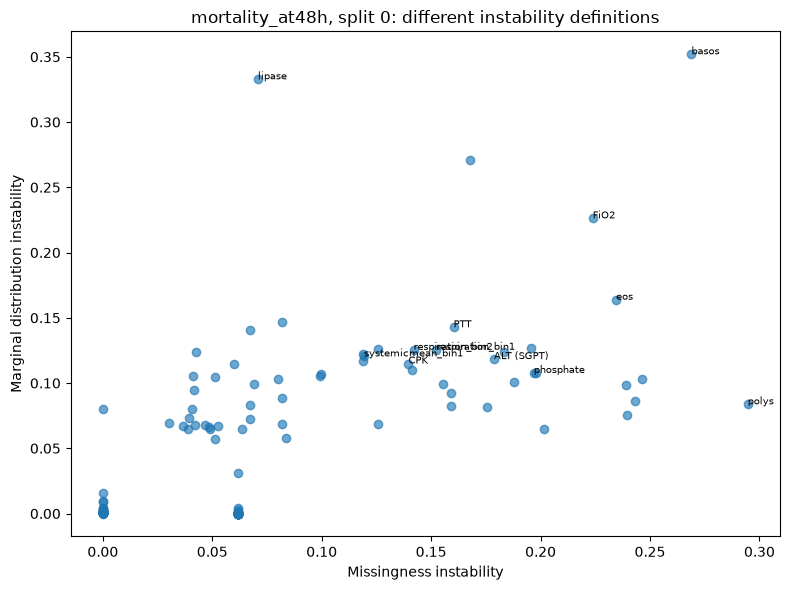

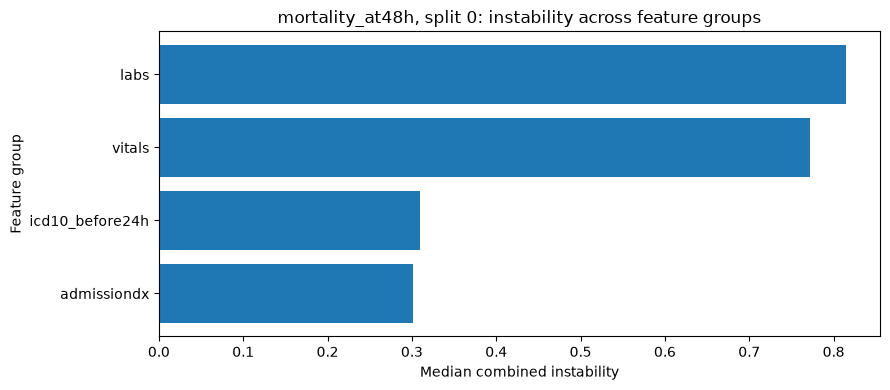

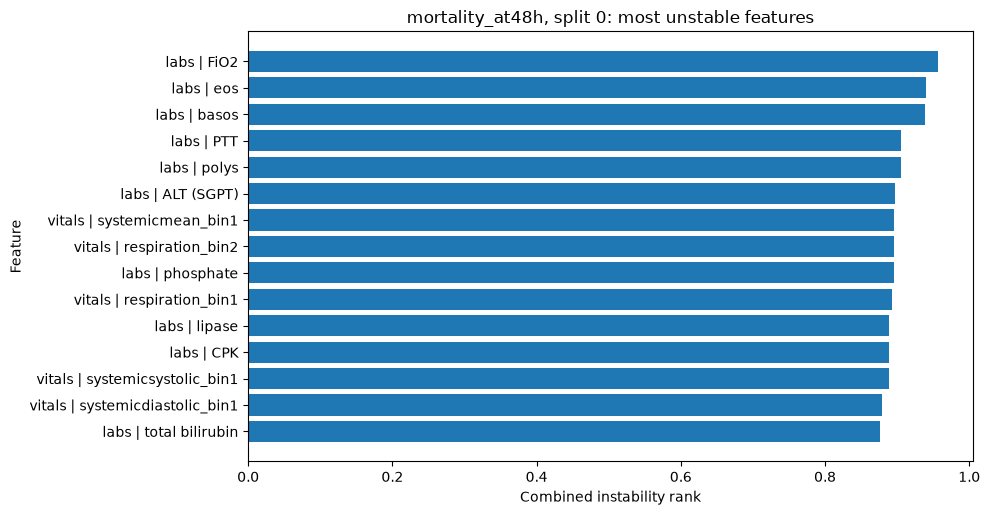


Model performance:


,outcome,split_id,feature_set,evaluation,hospitalid,n,positives,negatives,prevalence,auroc,auprc,auprc_excess_over_prevalence,brier,auroc_gap_from_internal
0,mortality_at48h,0,all_eligible_features,internal,internal,19328,816,18512,0.042219,0.836473,0.254976,0.212757,0.151846,0.000000
1,mortality_at48h,0,all_eligible_features,heldout,167,2815,131,2684,0.046536,0.844177,0.258074,0.211537,0.172564,-0.007704
2,mortality_at48h,0,all_eligible_features,heldout,197,1216,59,1157,0.048520,0.819478,0.253157,0.204638,0.138258,0.016996
3,mortality_at48h,0,all_eligible_features,heldout,384,794,24,770,0.030227,0.759307,0.250632,0.220405,0.113191,0.077166
4,mortality_at48h,0,all_eligible_features,heldout,390,889,49,840,0.055118,0.809159,0.283415,0.228297,0.211279,0.027314
5,mortality_at48h,0,all_eligible_features,heldout,434,309,21,288,0.067961,0.871362,0.435909,0.367947,0.176957,-0.034889
6,mortality_at48h,0,top_20_predictive,internal,internal,19328,816,18512,0.042219,0.815796,0.225752,0.183533,0.162654,0.000000
7,mortality_at48h,0,top_20_predictive,heldout,167,2815,131,2684,0.046536,0.808408,0.214508,0.167972,0.196779,0.007388
8,mortality_at48h,0,top_20_predictive,heldout,197,1216,59,1157,0.048520,0.818071,0.266480,0.217960,0.144197,-0.002275
9,mortality_at48h,0,top_20_predictive,heldout,384,794,24,770,0.030227,0.718182,0.203743,0.173516,0.120143,0.097614


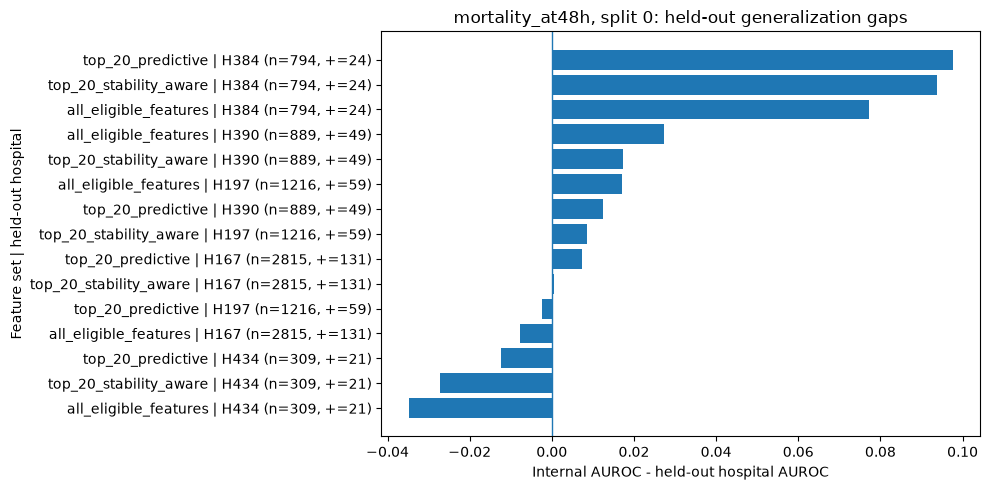


Outcome=mortality_at48h | split=1
Source hospitals=69 | Held-out hospitals=[338, 435, 248, 154, 440]

Most unstable features:


,feature,feature_group,feature_type,source_nonmissing,source_hospital_coverage,distribution_instability,missingness_instability,relationship_instability,combined_instability,predictive_utility,stability_aware_score
92,basos,labs,continuous,49301,66,0.350209,0.262007,0.081607,0.969048,0.063293,0.172619
14,FiO2,labs,continuous,31145,66,0.227091,0.228263,0.094027,0.964286,0.411729,0.510714
49,eos,labs,continuous,51480,69,0.158956,0.226780,0.077161,0.935714,0.193095,0.332143
60,CPK,labs,continuous,18707,69,0.123330,0.148564,0.099394,0.907143,0.164533,0.303571
37,phosphate,labs,continuous,28066,69,0.106077,0.196056,0.093821,0.902381,0.197162,0.363095
89,lipase,labs,continuous,10942,66,0.334952,0.074768,0.112204,0.902381,0.052189,0.184524
30,systemicsystolic_bin1,vitals,continuous,15672,62,0.127627,0.115513,0.104024,0.897619,0.238181,0.415476
24,PTT,labs,continuous,35964,68,0.148705,0.162626,0.073489,0.895238,0.248388,0.438095
62,polys,labs,continuous,48601,65,0.082921,0.289209,0.091633,0.890476,0.152876,0.290476
15,ALT (SGPT),labs,continuous,48953,69,0.119868,0.174270,0.079561,0.885714,0.275564,0.492857



Most stable features:


,feature,feature_group,feature_type,source_nonmissing,source_hospital_coverage,distribution_instability,missingness_instability,relationship_instability,combined_instability,predictive_utility,stability_aware_score
123,"admissiondx_Aneurysm repair, ventricular",admissiondx,binary,75983,69,0.000020,0.000000,0.000029,0.055952,0.000014,-0.013690
109,"admissiondx_Arthritis, septic",admissiondx,binary,75983,69,0.000063,0.000000,0.000072,0.117857,0.000041,0.083929
114,"admissiondx_Anastomosis, vascular",admissiondx,binary,75983,69,0.000053,0.000000,0.000092,0.122619,0.000027,0.045833
105,admissiondx_Amyotrophic lateral sclerosis,admissiondx,binary,75983,69,0.000082,0.000000,0.000102,0.144048,0.000055,0.099405
97,admissiondx_Adrenal neoplasm (including pheoch...,admissiondx,binary,75983,69,0.000110,0.000000,0.000114,0.160714,0.000069,0.148214
94,admissiondx_Addisons disease,admissiondx,binary,75983,69,0.000138,0.000000,0.000126,0.177381,0.000082,0.161310
126,C00.2,icd10_before24h,binary,68634,69,0.000021,0.056302,0.000027,0.190476,0.000015,-0.034524
129,B95.7,icd10_before24h,binary,68634,69,0.000022,0.056302,0.000031,0.203571,0.000015,-0.041071
128,B15.9,icd10_before24h,binary,68634,69,0.000022,0.056302,0.000031,0.203571,0.000015,-0.041071
127,A31.9,icd10_before24h,binary,68634,69,0.000022,0.056302,0.000031,0.203571,0.000015,-0.041071



Spearman correlation between instability definitions:


,distribution_instability,missingness_instability,relationship_instability
distribution_instability,1.000000,0.511560,0.943697
missingness_instability,0.511560,1.000000,0.518793
relationship_instability,0.943697,0.518793,1.000000



Feature-group summary:


,outcome,split_id,feature_group,n_features,median_distribution_instability,median_missingness_instability,median_relationship_instability,median_combined_instability,median_predictive_utility,enough_features_for_comparison
0,mortality_at48h,1,admissiondx,40,0.001059,0.000000,0.001387,0.296429,0.000616,True
1,mortality_at48h,1,icd10_before24h,40,0.000112,0.056302,0.000140,0.300000,0.000061,True
2,mortality_at48h,1,demographic,3,0.071738,0.023879,0.053491,0.528571,0.021440,False
3,mortality_at48h,1,vitals,17,0.107576,0.078982,0.071671,0.752381,0.216568,True
4,mortality_at48h,1,labs,40,0.099553,0.156606,0.069040,0.834524,0.187351,True


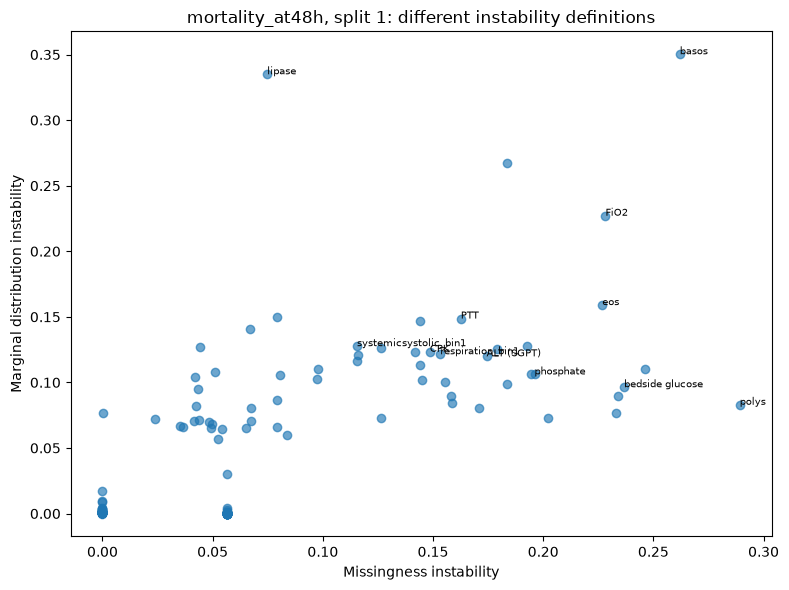

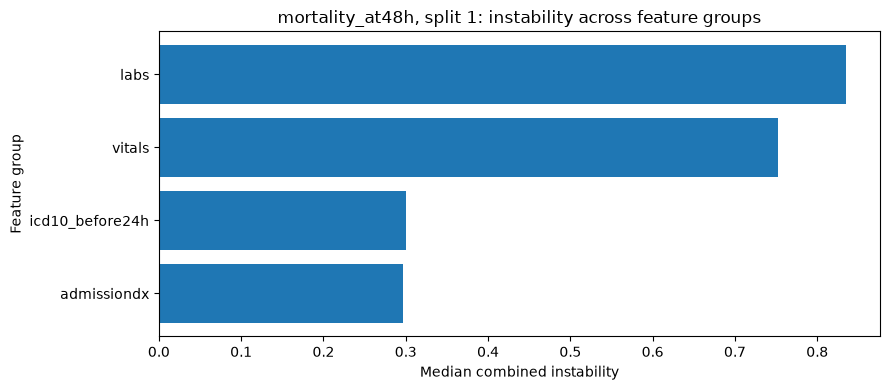

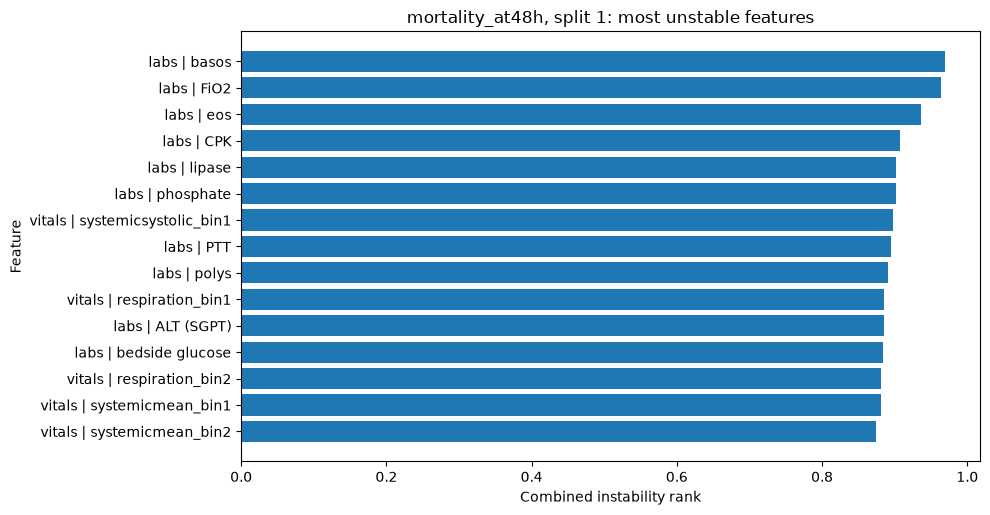


Model performance:


,outcome,split_id,feature_set,evaluation,hospitalid,n,positives,negatives,prevalence,auroc,auprc,auprc_excess_over_prevalence,brier,auroc_gap_from_internal
0,mortality_at48h,1,all_eligible_features,internal,internal,18996,814,18182,0.042851,0.840887,0.266610,0.223759,0.150947,0.000000
1,mortality_at48h,1,all_eligible_features,heldout,154,891,36,855,0.040404,0.849318,0.254598,0.214194,0.210909,-0.008431
2,mortality_at48h,1,all_eligible_features,heldout,248,1354,47,1307,0.034712,0.870078,0.329111,0.294399,0.141520,-0.029191
3,mortality_at48h,1,all_eligible_features,heldout,338,3292,131,3161,0.039793,0.841694,0.254996,0.215202,0.123754,-0.000808
4,mortality_at48h,1,all_eligible_features,heldout,435,1021,45,976,0.044074,0.813752,0.241278,0.197204,0.181050,0.027134
5,mortality_at48h,1,all_eligible_features,heldout,440,1122,38,1084,0.033868,0.848053,0.326820,0.292952,0.150703,-0.007166
6,mortality_at48h,1,top_20_predictive,internal,internal,18996,814,18182,0.042851,0.818940,0.237965,0.195114,0.161015,0.000000
7,mortality_at48h,1,top_20_predictive,heldout,154,891,36,855,0.040404,0.844542,0.230748,0.190344,0.215331,-0.025602
8,mortality_at48h,1,top_20_predictive,heldout,248,1354,47,1307,0.034712,0.856078,0.312930,0.278218,0.152415,-0.037138
9,mortality_at48h,1,top_20_predictive,heldout,338,3292,131,3161,0.039793,0.831689,0.230742,0.190949,0.139902,-0.012750


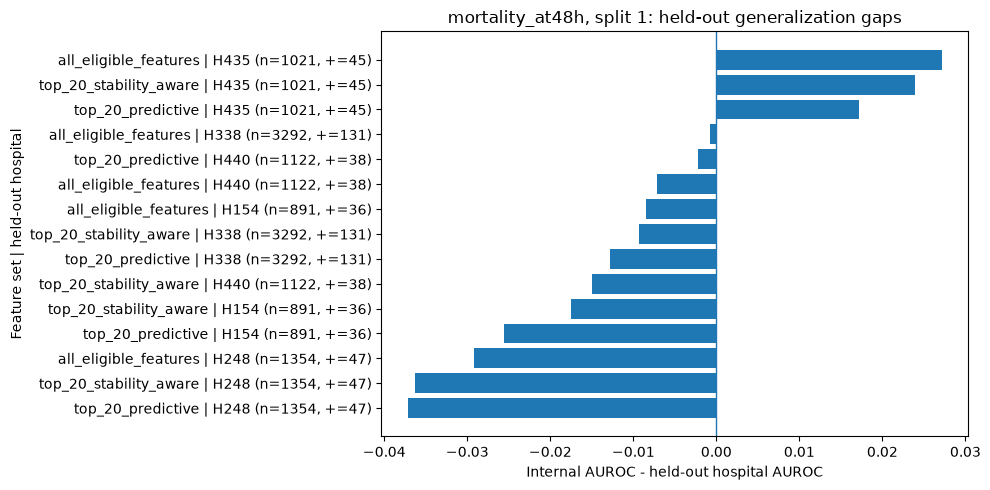


Outcome=mortality_at48h | split=2
Source hospitals=69 | Held-out hospitals=[449, 443, 403, 154, 336]


In [ ]:
# Repeat across outcomes and multiple hospital splits.

all_instability_tables = []
all_group_summaries = []
all_performance_tables = []
split_records = []

for outcome in OUTCOMES:
    eligible = eligible_hospitals(
        patient_agg,
        outcome,
    )
    splits = make_hospital_splits(
        eligible,
        outcome,
    )

    for split in splits:
        split_id = split['split_id']
        source_hospitals = split['source_hospitals']
        heldout_hospitals = split['heldout_hospitals']

        print("\n" + "=" * 80)
        print(
            f"Outcome={outcome} | split={split_id}"
        )
        print(
            f"Source hospitals={len(source_hospitals)} | "
            f"Held-out hospitals={heldout_hospitals}"
        )

        outcome_y = coerce_binary(
            patient_agg[outcome]
        )

        analysis_data = patient_agg.loc[
            outcome_y.notna()
        ].copy()
        analysis_data[outcome] = (
            outcome_y.loc[outcome_y.notna()]
            .astype(int)
        )

        source_data = analysis_data[
            analysis_data[hospital_col].isin(
                source_hospitals
            )
        ].copy()

        heldout_data = analysis_data[
            analysis_data[hospital_col].isin(
                heldout_hospitals
            )
        ].copy()

        source_dev, internal = (
            split_source_internal(
                source_data,
                outcome,
            )
        )

        split_records.append({
            'outcome': outcome,
            'split_id': split_id,
            'n_source_hospitals': len(
                source_hospitals
            ),
            'heldout_hospitals': ','.join(
                map(str, heldout_hospitals)
            ),
            'n_source_patients': len(source_data),
            'n_source_dev': len(source_dev),
            'n_internal': len(internal),
            'n_heldout': len(heldout_data),
        })

        instability_table = (
            build_instability_table(
                source_dev,
                outcome,
            )
        )

        instability_table.insert(
            0,
            'outcome',
            outcome,
        )
        instability_table.insert(
            1,
            'split_id',
            split_id,
        )

        if instability_table.empty:
            print(
                "No features passed source-only "
                "coverage filters."
            )
            continue

        print_extremes(
            instability_table,
            n=10,
        )

        rank_corr = compare_metric_rankings(
            instability_table
        )
        print(
            "\nSpearman correlation between "
            "instability definitions:"
        )
        display(rank_corr)

        group_summary = (
            comparable_group_summary(
                instability_table
            )
        )
        group_summary = (
            group_summary.reset_index()
        )
        group_summary.insert(
            0,
            'outcome',
            outcome,
        )
        group_summary.insert(
            1,
            'split_id',
            split_id,
        )

        print("\nFeature-group summary:")
        display(group_summary)

        split_dir = (
            OUTPUT_DIR
            / outcome
            / f"split_{split_id}"
        )
        split_dir.mkdir(
            parents=True,
            exist_ok=True,
        )

        instability_table.to_csv(
            split_dir / 'feature_instability.csv',
            index=False,
        )
        rank_corr.to_csv(
            split_dir
            / 'instability_metric_correlations.csv'
        )
        group_summary.to_csv(
            split_dir / 'feature_group_summary.csv',
            index=False,
        )

        plot_instability_figures(
            instability_table,
            group_summary.set_index(
                'feature_group'
            ),
            outcome,
            split_id,
            split_dir,
        )

        feature_sets_for_model = (
            choose_feature_sets(
                instability_table
            )
        )

        split_perf = []
        for label, features in (
            feature_sets_for_model.items()
        ):
            perf, _ = evaluate_model(
                source_dev,
                internal,
                heldout_data,
                features,
                outcome,
                label,
                split_id,
            )
            perf.insert(
                0,
                'outcome',
                outcome,
            )
            split_perf.append(perf)

        if split_perf:
            performance = pd.concat(
                split_perf,
                ignore_index=True,
            )

            performance.to_csv(
                split_dir / 'model_performance.csv',
                index=False,
            )

            print("\nModel performance:")
            display(performance)

            plot_generalization_gap(
                performance,
                outcome,
                split_id,
                split_dir,
            )

            all_performance_tables.append(
                performance
            )

        all_instability_tables.append(
            instability_table
        )
        all_group_summaries.append(
            group_summary
        )

# Combined files across outcomes/splits.
combined_instability = (
    pd.concat(
        all_instability_tables,
        ignore_index=True,
    )
    if all_instability_tables
    else pd.DataFrame()
)

combined_groups = (
    pd.concat(
        all_group_summaries,
        ignore_index=True,
    )
    if all_group_summaries
    else pd.DataFrame()
)

combined_performance = (
    pd.concat(
        all_performance_tables,
        ignore_index=True,
    )
    if all_performance_tables
    else pd.DataFrame()
)

split_summary = pd.DataFrame(
    split_records
)

combined_instability.to_csv(
    OUTPUT_DIR / 'all_feature_instability.csv',
    index=False,
)
combined_groups.to_csv(
    OUTPUT_DIR / 'all_feature_group_summaries.csv',
    index=False,
)
combined_performance.to_csv(
    OUTPUT_DIR / 'all_model_performance.csv',
    index=False,
)
split_summary.to_csv(
    OUTPUT_DIR / 'hospital_splits.csv',
    index=False,
)

print("\nSaved combined outputs to:", OUTPUT_DIR.resolve())

In [ ]:
# Cross-outcome / cross-split summary figures and tables.

if not combined_groups.empty:
    comparable = combined_groups[
        combined_groups[
            'enough_features_for_comparison'
        ]
    ].copy()

    if not comparable.empty:
        pivot = comparable.pivot_table(
            index='feature_group',
            columns='outcome',
            values='median_combined_instability',
            aggfunc='median',
        )

        print(
            "Median feature-group instability "
            "across hospital splits:"
        )
        display(pivot)

        ax = pivot.plot(
            kind='bar',
            figsize=(10, 6),
        )
        ax.set_ylabel(
            'Median combined instability'
        )
        ax.set_xlabel('Feature group')
        ax.set_title(
            'Feature-group instability across outcomes'
        )
        plt.xticks(rotation=30, ha='right')
        plt.tight_layout()
        plt.savefig(
            OUTPUT_DIR
            / 'feature_groups_across_outcomes.png',
            dpi=200,
            bbox_inches='tight',
        )
        plt.show()


if not combined_performance.empty:
    heldout = combined_performance[
        combined_performance[
            'evaluation'
        ].eq('heldout')
    ].copy()

    if not heldout.empty:
        gap_summary = (
            heldout.groupby(
                ['outcome', 'feature_set']
            )
            .agg(
                n_hospital_evaluations=(
                    'hospitalid',
                    'count',
                ),
                median_auroc_gap=(
                    'auroc_gap_from_internal',
                    'median',
                ),
                median_heldout_auroc=(
                    'auroc',
                    'median',
                ),
                median_auprc_excess=(
                    'auprc_excess_over_prevalence',
                    'median',
                ),
            )
            .reset_index()
        )

        print(
            "Held-out performance summarized across "
            "hospital splits:"
        )
        display(gap_summary)

        gap_summary.to_csv(
            OUTPUT_DIR
            / 'generalization_gap_summary.csv',
            index=False,
        )


print(
    "\nWeek 3 interpretation reminders:\n"
    "- Compare whether the three instability metrics rank the same features.\n"
    "- Only compare feature groups with enough valid features.\n"
    "- Treat stability-aware feature selection as exploratory.\n"
    "- Do not claim that instability causes poor generalization.\n"
    "- Look for patterns that persist across outcomes and hospital splits."
)